# Самостоятельная работа 3. Анализ клеток ткани яичника

Шилина Виктория Владимировна

Для работы выбрана проба GSM5599220 - неопухолевая ткань яичника человека. Она входит в серию [GSE184880](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE184880). [Страница пробы в GEO](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM5599220).

## Подготовка

Устанавливаем Scanpy, CellTypist и библиотеки для кластеризации. Версии закреплены, чтобы при повторном запуске использовалось то же окружение.

In [2]:
%pip install -q numpy==2.2.6 numba==0.61.2

In [1]:
pip install -q scanpy==1.11.5 celltypist==1.7.1 pandas==2.2.3 scipy==1.15.3 anndata==0.11.4 scikit-learn==1.6.1 matplotlib==3.10.3 h5py==3.13.0 igraph==0.11.9 leidenalg==0.10.2 scikit-misc==0.5.1 "zarr<3" seaborn==0.13.2

In [3]:
from pathlib import Path
import urllib.request
import tarfile
import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
import scanpy as sc
import celltypist

DATA = Path('data/ovary')
OUT = Path('results_ovary')
DATA.mkdir(parents=True, exist_ok=True)
OUT.mkdir(exist_ok=True)

sc.settings.verbosity = 1
sc.settings.set_figure_params(dpi=100, frameon=False, figsize=(6, 5))
np.random.seed(42)

/usr/local/lib/python3.13/dist-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


## 1. Данные и контроль качества

Авторы исходной работы изучали клеточный состав неопухолевой ткани яичника и серозной карциномы. Для самостоятельного анализа я взяла одну неопухолевую пробу, полученную методом 10x Genomics. По ней можно описать состав конкретного образца, но нельзя оценить различия между нормой и опухолью. [Xu et al., 2022](https://doi.org/10.1158/1078-0432.CCR-22-0296).

Скачиваем матрицу UMI, список генов и баркоды клеток. В матрице уже отобраны клеточные баркоды; пустые капли отдельно не анализируются.

In [4]:
url = 'https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM5599nnn/GSM5599220/suppl/'
prefix = 'GSM5599220_Norm1'

for name in ['barcodes.tsv.gz', 'genes.tsv.gz', 'matrix.mtx.gz']:
    filename = prefix + '.' + name
    if not (DATA / filename).exists():
        urllib.request.urlretrieve(url + filename, DATA / filename)

matrix = sio.mmread(DATA / (prefix + '.matrix.mtx.gz'))
genes = pd.read_csv(DATA / (prefix + '.genes.tsv.gz'), sep='\t', header=None)
barcodes = pd.read_csv(DATA / (prefix + '.barcodes.tsv.gz'), sep='\t', header=None)

adata = sc.AnnData(matrix.T.tocsr().astype('float32'))
adata.var_names = genes[1].values
adata.obs_names = barcodes[0].values
adata.var_names_make_unique()

print('До фильтрации:', adata.n_obs, 'клеток и', adata.n_vars, 'генов')
adata

До фильтрации: 6370 клеток и 27984 генов


AnnData object with n_obs × n_vars = 6370 × 27984

,total_counts,n_genes_by_counts,pct_counts_mt
count,6370.000000,6370.000000,6370.000000
mean,8934.171875,2352.106907,11.590736
std,8375.545898,942.250921,7.562902
min,505.000000,62.000000,0.076482
1%,1019.210000,461.450000,2.721037
5%,2446.450000,977.000000,6.391133
50%,8095.500000,2276.500000,10.014880
95%,16453.600000,3826.000000,21.534949
99%,38384.410000,5862.960000,43.998978
max,178728.000000,10592.000000,96.528145


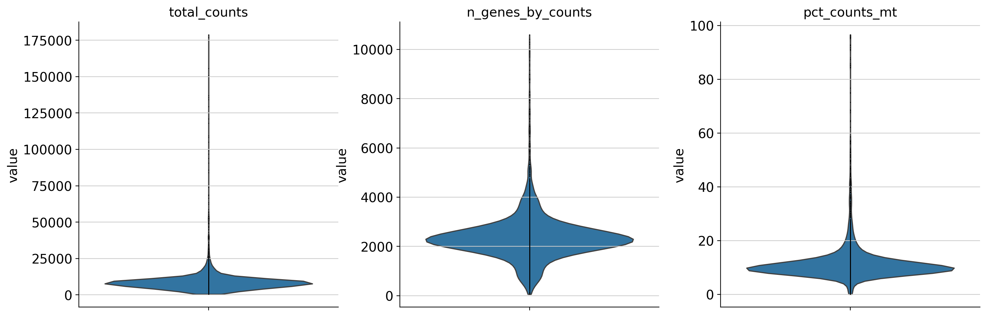

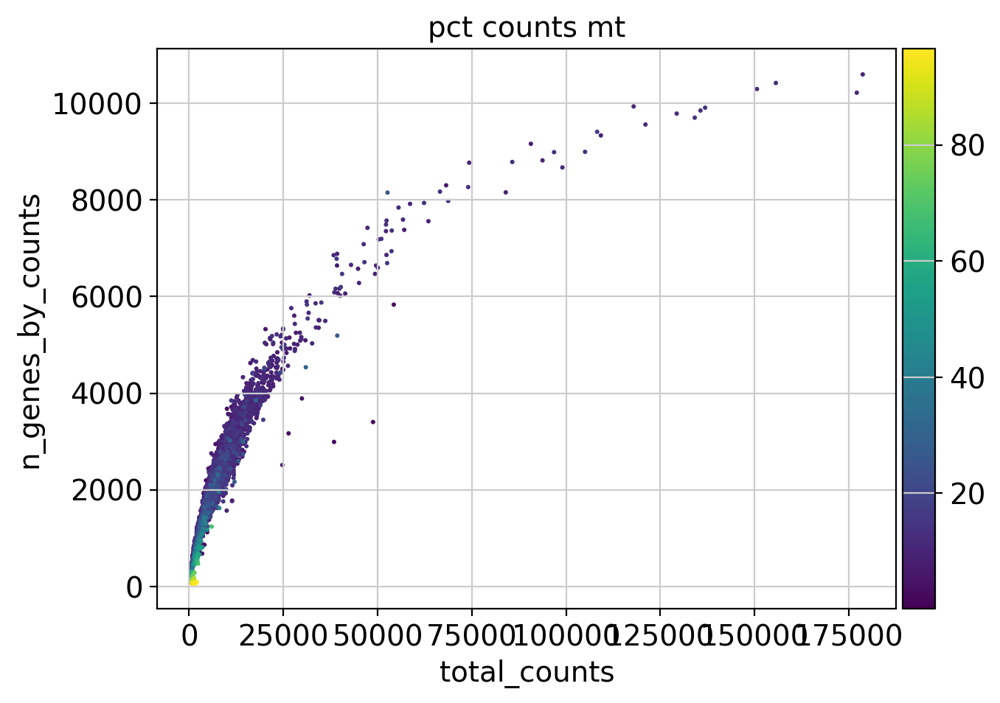

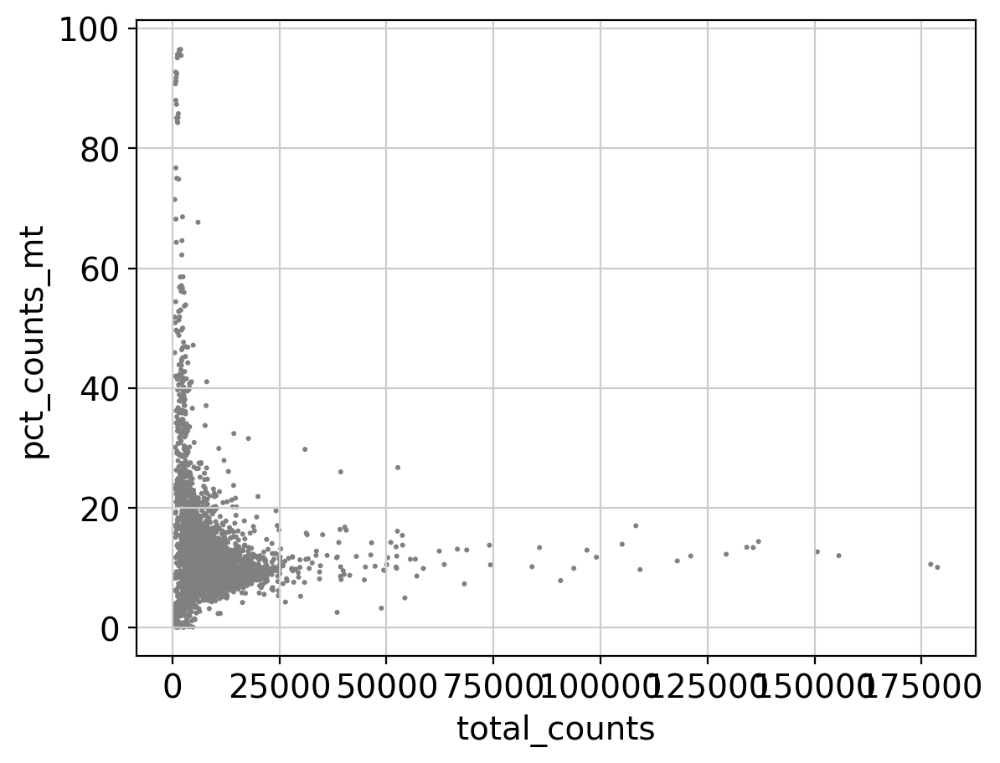

In [5]:
adata.var['mt'] = adata.var_names.str.startswith('MT-')
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], percent_top=None, inplace=True)

qc_columns = ['total_counts', 'n_genes_by_counts', 'pct_counts_mt']
display(adata.obs[qc_columns].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))

sc.pl.violin(adata, qc_columns, jitter=False, multi_panel=True)
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', color='pct_counts_mt')
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt')

По распределениям я оставила клетки с числом генов от 200 до 5999, количеством UMI меньше 40 000 и долей митохондриальных UMI меньше 20%. В исходной пробе медиана митохондриальной доли около 10%, поэтому порог 5% из примера с PBMC здесь удалил бы слишком много клеток.

Нижний порог по генам убирает бедные транскриптами баркоды. Верхние пороги по генам и UMI находятся примерно у верхнего 1% распределения и отсекают крайние значения, среди которых могут быть мультиплеты. Порог по митохондриальным генам убирает клетки с признаками повреждения. Эти пороги не заменяют отдельную проверку дублетов. Также удаляю гены, обнаруженные менее чем в трёх оставшихся клетках.

Удалено клеток: 441
После фильтрации: 5929 клеток и 17704 генов


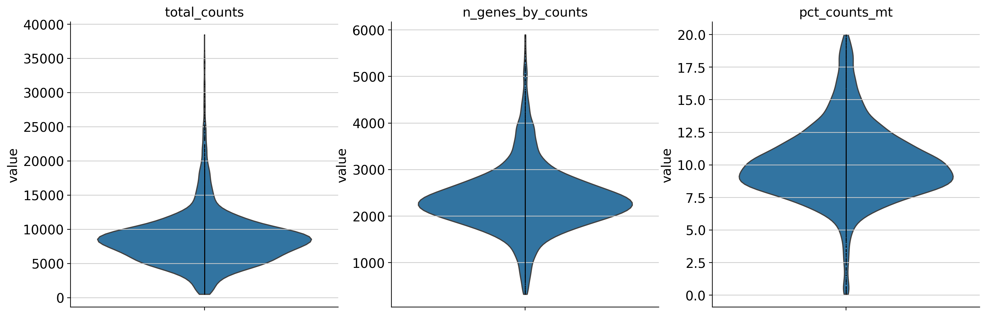

In [6]:
n_before = adata.n_obs
adata = adata[
    (adata.obs['n_genes_by_counts'] >= 200)
    & (adata.obs['n_genes_by_counts'] < 6000)
    & (adata.obs['total_counts'] < 40000)
    & (adata.obs['pct_counts_mt'] < 20)
].copy()

sc.pp.filter_genes(adata, min_cells=3)
adata.layers['counts'] = adata.X.copy()

print('Удалено клеток:', n_before - adata.n_obs)
print('После фильтрации:', adata.n_obs, 'клеток и', adata.n_vars, 'генов')
sc.pl.violin(adata, qc_columns, jitter=False, multi_panel=True)

## 2. Нормализация и HVG

После QC осталось 5929 клеток и 17 704 гена. Сохраняю исходные UMI в `layers['counts']`, а в `.X` выполняю нормализацию до 10 000 counts на клетку и `log1p`.

Для PCA выбрано 2000 высоковариабельных генов. Они помогают выделить различия между клетками и уменьшают число малоинформативных признаков. Все гены при этом остаются в матрице: они ещё нужны для поиска маркеров. Метод `seurat_v3` требует исходные counts, поэтому HVG рассчитываются по сохранённому слою.

Число HVG: 2000


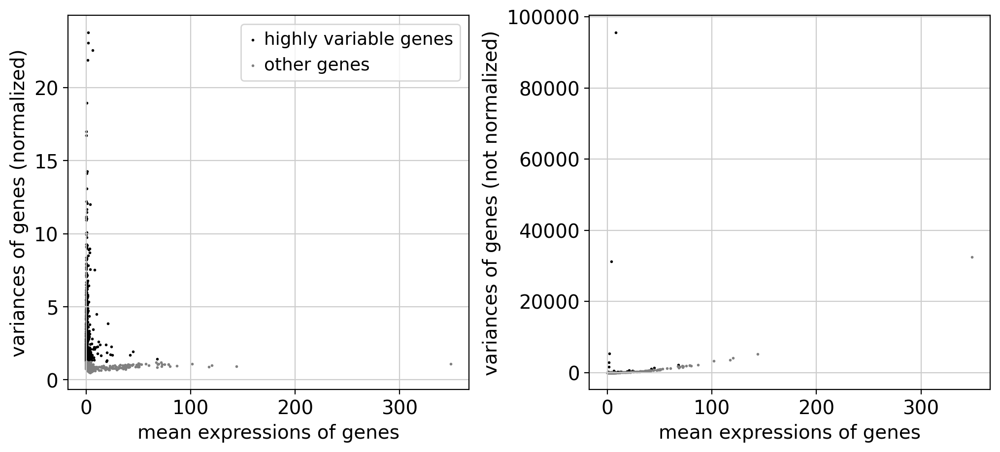

,means,variances,variances_norm
CCL3,1.610727,81.142975,23.769016
CCL4L2,1.623377,78.290486,23.066792
CCL4,6.061730,583.299158,22.568846
TAGLN,1.425030,74.282545,21.870813
MYH11,0.602462,18.678476,18.944138
LST1,0.151965,6.017895,16.995041
AIF1,0.151459,6.700066,16.722764
ACTA2,0.871985,22.043157,14.280488
FCER1G,0.268005,5.371650,14.265067
HLA-DRA,0.539383,32.708342,14.118747


In [7]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, layer='counts', flavor='seurat_v3', n_top_genes=2000)

print('Число HVG:', adata.var['highly_variable'].sum())
sc.pl.highly_variable_genes(adata)

top_hvg = adata.var.sort_values('variances_norm', ascending=False).head(10)
display(top_hvg[['means', 'variances', 'variances_norm']])

Среди десяти наиболее вариабельных генов есть хемокины, иммунные гены и гены сократительного аппарата. Значит, отбор HVG улавливает различия между клеточными популяциями. При этом высокая вариабельность ещё не делает ген специфичным маркером.

In [8]:
hvg_functions = pd.DataFrame({
    'Ген': ['CCL3', 'CCL4L2', 'CCL4', 'TAGLN', 'MYH11', 'LST1', 'AIF1', 'ACTA2', 'FCER1G', 'HLA-DRA'],
    'Функция': [
        'Хемокин, участвующий в привлечении иммунных клеток',
        'CCL4-подобный хемокин; сходные копии гена нужно различать при сопоставлении',
        'Хемокин, участвующий в миграции иммунных клеток',
        'Актин-связывающий белок сократительного цитоскелета',
        'Тяжёлая цепь гладкомышечного миозина',
        'Мембранный адаптер миелоидных клеток',
        'Связывает актин и кальций, связан с активацией макрофагов',
        'Альфа-актин гладких мышц',
        'Сигнальная субъединица Fc-рецепторов',
        'Альфа-цепь MHC II, участвует в представлении антигена'
    ],
    'NCBI Gene': [6348, 9560, 6351, 6876, 4629, 7940, 199, 59, 2207, 3122]
})
display(hvg_functions)
hvg_functions.to_csv(OUT / 'top10_hvg_functions.csv', index=False)

,Ген,Функция,NCBI Gene
0,CCL3,"Хемокин, участвующий в привлечении иммунных кл...",6348
1,CCL4L2,CCL4-подобный хемокин; сходные копии гена нужн...,9560
2,CCL4,"Хемокин, участвующий в миграции иммунных клеток",6351
3,TAGLN,Актин-связывающий белок сократительного цитоск...,6876
4,MYH11,Тяжёлая цепь гладкомышечного миозина,4629
5,LST1,Мембранный адаптер миелоидных клеток,7940
6,AIF1,"Связывает актин и кальций, связан с активацией...",199
7,ACTA2,Альфа-актин гладких мышц,59
8,FCER1G,Сигнальная субъединица Fc-рецепторов,2207
9,HLA-DRA,"Альфа-цепь MHC II, участвует в представлении а...",3122


## 3. PCA и кластеризация

PCA строим по 2000 HVG на лог-нормализованных данных. Отдельно до единичной дисперсии гены не масштабируем. На графике объяснённой дисперсии основной вклад приходится на первые компоненты, затем он плавно уменьшается. Для графа соседей я выбрала 30 PC, чтобы сохранить и менее выраженные различия небольших популяций.

Использую 15 соседей и сравниваю Leiden при `resolution=0.3` и `1.0`. Оба разбиения строятся на одном графе.

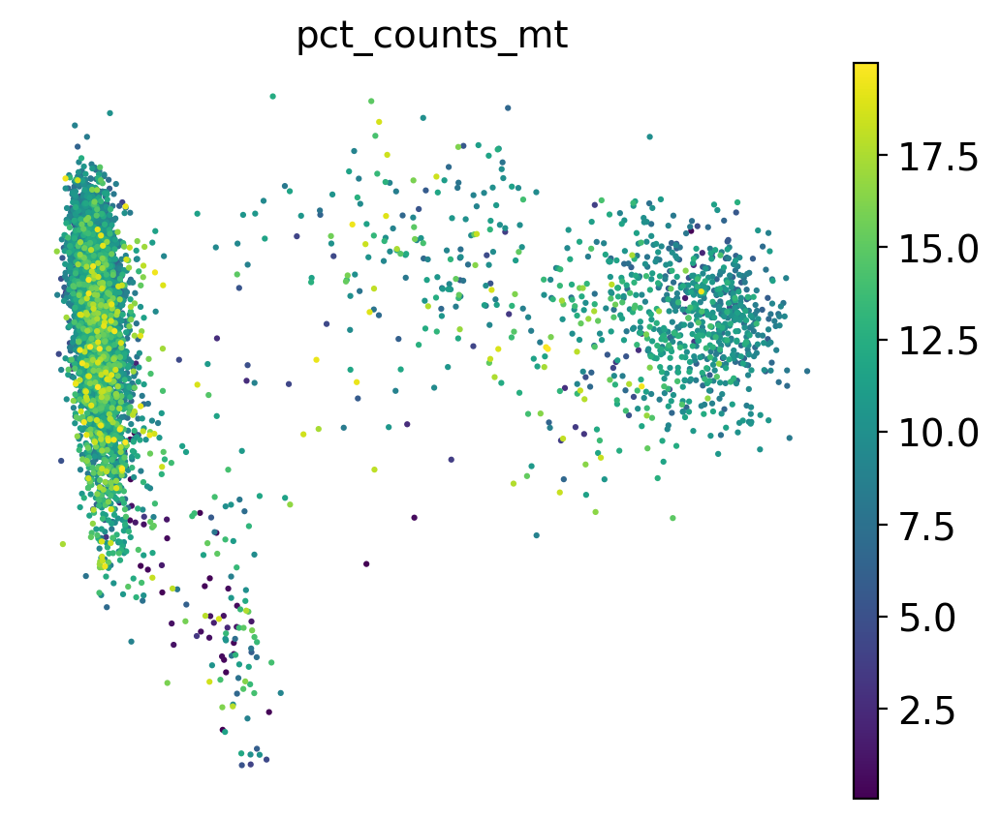

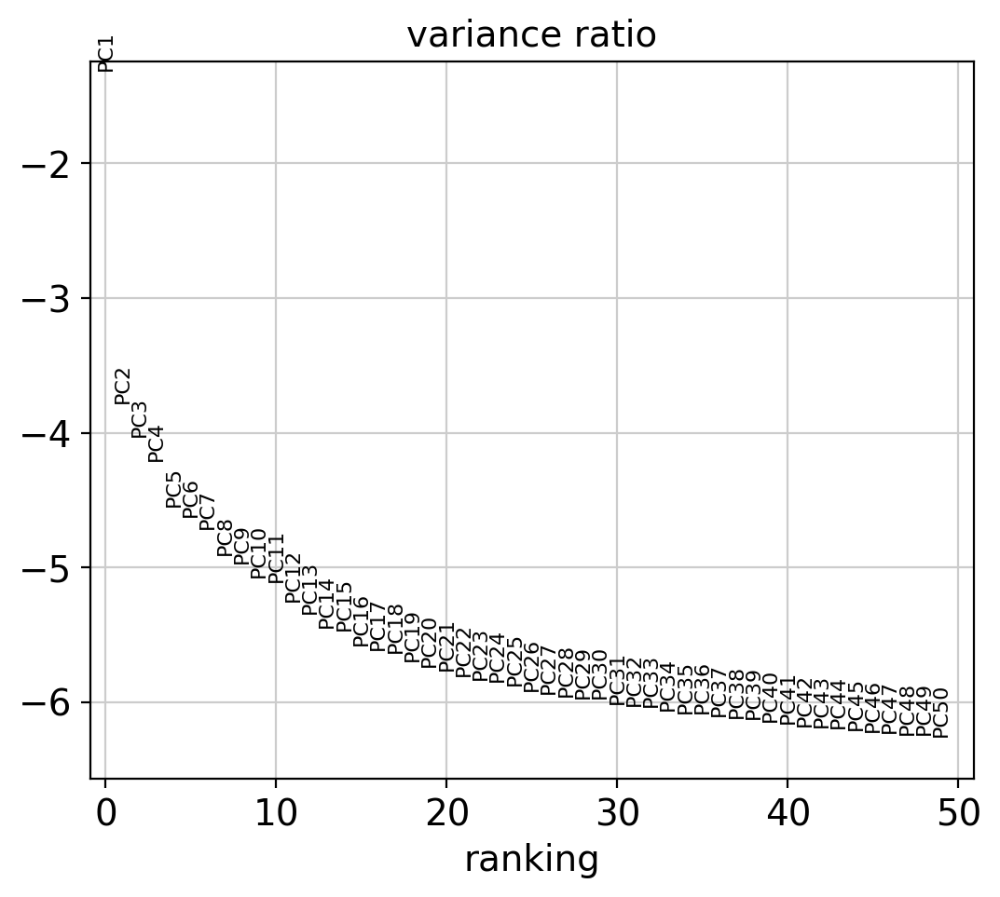

In [9]:
sc.tl.pca(adata, n_comps=50, mask_var='highly_variable', random_state=42)
sc.pl.pca(adata, color='pct_counts_mt')
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

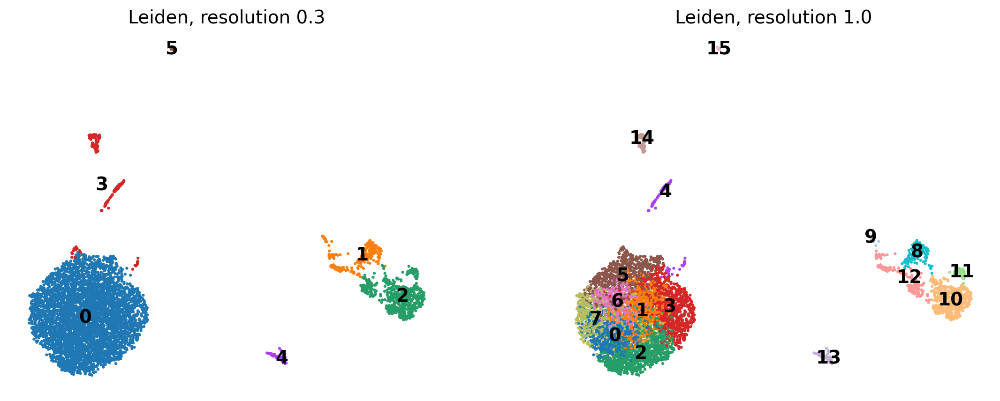

In [10]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30, random_state=42)
for resolution in [0.3,1.0]:
    sc.tl.leiden(adata, resolution=resolution, key_added=f'leiden_{resolution}',
                 flavor='igraph', n_iterations=2, directed=False, random_state=42)
sc.tl.umap(adata, min_dist=.3, random_state=42)
sc.pl.umap(adata, color=['leiden_0.3','leiden_1.0'], ncols=2, legend_loc='on data',
           title=['Leiden, resolution 0.3','Leiden, resolution 1.0'])

In [11]:
print('Resolution 0.3:')
display(adata.obs['leiden_0.3'].value_counts().sort_index())
print('Resolution 1.0:')
display(adata.obs['leiden_1.0'].value_counts().sort_index())

cross_resolution = pd.crosstab(adata.obs['leiden_0.3'], adata.obs['leiden_1.0'])
display(cross_resolution)
cross_resolution.to_csv(OUT / 'cluster_transitions.csv')

Resolution 0.3:


,count
leiden_0.3,
0,4773
1,265
2,618
3,175
4,81
5,17


Resolution 1.0:


,count
leiden_1.0,
0,692
1,643
2,934
3,861
4,101
5,652
6,426
7,568
8,157


leiden_1.0,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
leiden_0.3,,,,,,,,,,,,,,,,
0,692,643,934,861,12,637,426,568,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,152,28,0,0,85,0,0,0
2,0,0,0,0,0,0,0,0,5,0,469,50,94,0,0,0
3,0,0,0,0,89,15,0,0,0,0,0,0,0,0,71,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,81,0,0
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,17


При resolution=0.3 получилось 6 кластеров, при resolution=1.0 — 16. Крупнейший кластер 0 при низком разрешении разделился в основном на стромальные кластеры 0–3 и 5–7. Разбиения не полностью вложены: при смене resolution часть клеток меняет группу.

При resolution=0.3 крупнейший кластер содержит 4773 клетки, а при resolution=1.0 — 934 клетки. Повышение разрешения разделило крупную группу на несколько меньших.

Каждый новый кластер не обязательно является отдельным типом клеток. Он может отражать состояние или технические различия внутри одной популяции. Расстояния между островами UMAP также не позволяют судить о происхождении клеток.

## 4. Ручная аннотация

Для аннотации выбрано `resolution=1.0`. Сначала нахожу маркеры каждого кластера относительно остальных клеток с помощью теста Wilcoxon и поправки Benjamini–Hochberg. Оставляю положительные маркеры с `pvals_adj < 0.05`, `logfoldchanges > 0.5` и экспрессией хотя бы в 10% клеток кластера.

Затем проверяю несколько известных маркеров вместе: их среднюю экспрессию и долю клеток, в которых они обнаружены. Тесты здесь помогают описать группы внутри одной пробы. Они не показывают, насколько различия воспроизводятся между пациентами.

,group,names,scores,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,0,EGR1,22.528299,1.4584,0.0,1.0000,0.8524
1,0,JUN,22.209499,0.9865,0.0,1.0000,0.9807
2,0,JUNB,21.374001,1.1689,0.0,1.0000,0.9525
3,0,FOS,20.666700,0.9960,0.0,1.0000,0.9828
4,0,FOSB,18.270599,0.7815,0.0,1.0000,0.9706
...,...,...,...,...,...,...,...
265563,15,TNFRSF11A,43.937500,9.5137,0.0,0.5882,0.0014
265564,15,PKHD1L1,43.558899,9.6333,0.0,0.7647,0.0030
265565,15,C6orf141,42.863098,9.3800,0.0,0.7647,0.0032
265566,15,CCL21,41.537399,13.0462,0.0,0.9412,0.0061


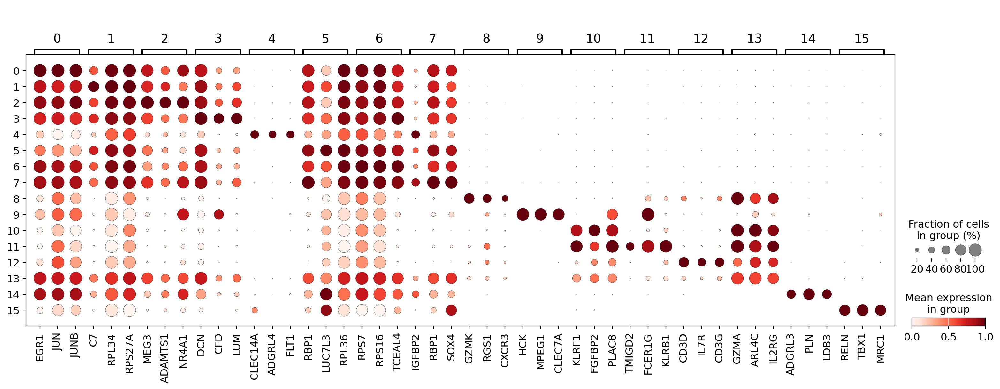

In [12]:
CLUSTER = 'leiden_1.0'
sc.tl.rank_genes_groups(adata, groupby=CLUSTER, method='wilcoxon', reference='rest',
                        use_raw=False, tie_correct=True, corr_method='benjamini-hochberg',
                        pts=True, key_added='markers')
markers = sc.get.rank_genes_groups_df(adata, group=None, key='markers')
markers.to_csv(OUT/'markers_all.csv', index=False)
filtered = markers[(markers.pvals_adj<.05) & (markers.logfoldchanges>.5)
                   & (markers.pct_nz_group>=.1)].copy()
filtered.to_csv(OUT/'markers_filtered.csv', index=False)
top_markers = filtered.groupby('group', observed=True, sort=False).head(8)
display(top_markers[['group','names','scores','logfoldchanges','pvals_adj',
                     'pct_nz_group','pct_nz_reference']].round(4))
sc.pl.rank_genes_groups_dotplot(adata, key='markers', groupby=CLUSTER, n_genes=3,
                               use_raw=False, standard_scale='var', dendrogram=False)

Для проверки использую маркеры из [исходной статьи](https://pmc.ncbi.nlm.nih.gov/articles/PMC9662915/): DCN/LUM/коллагены для стромы, CD3D/CD3E/TRAC для T-клеток, LYZ/LST1/C1QA для миелоидных клеток, PECAM1/CLDN5/VWF для эндотелия и ACTA2/MYH11/TAGLN для гладкомышечных клеток. NK-подобные клетки проверяю по NKG7/GNLY/KLRD1 вместе с T-клеточными маркерами.

Отдельно смотрю PROX1/PDPN/CCL21 для лимфатического эндотелия и EPCAM/KRT19 для эпителиальных клеток. STAR или FOXL2 в строме недостаточно, чтобы уверенно назвать клетки стероидогенными или гранулёзными.

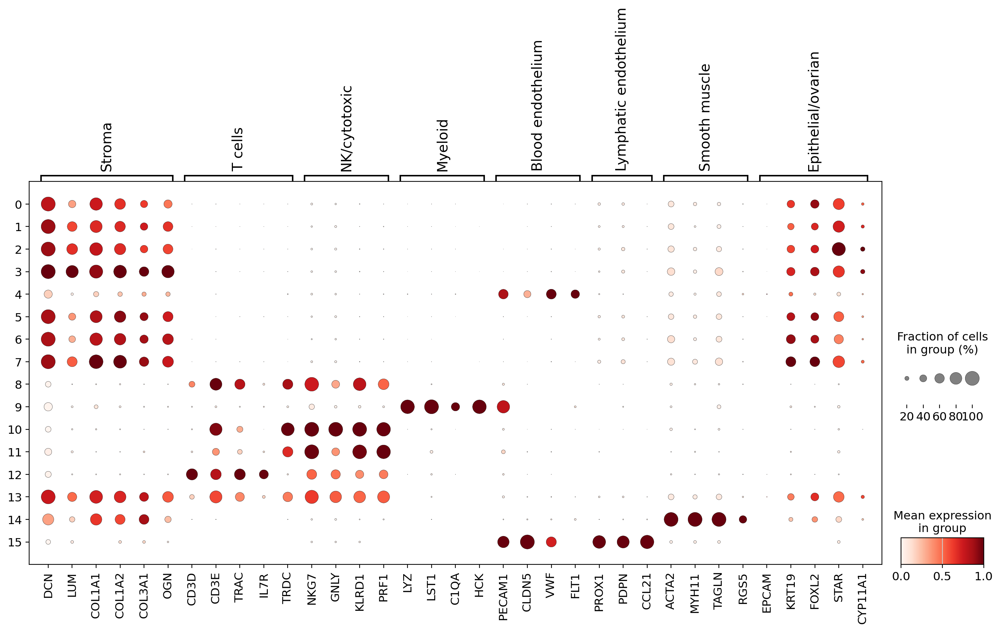

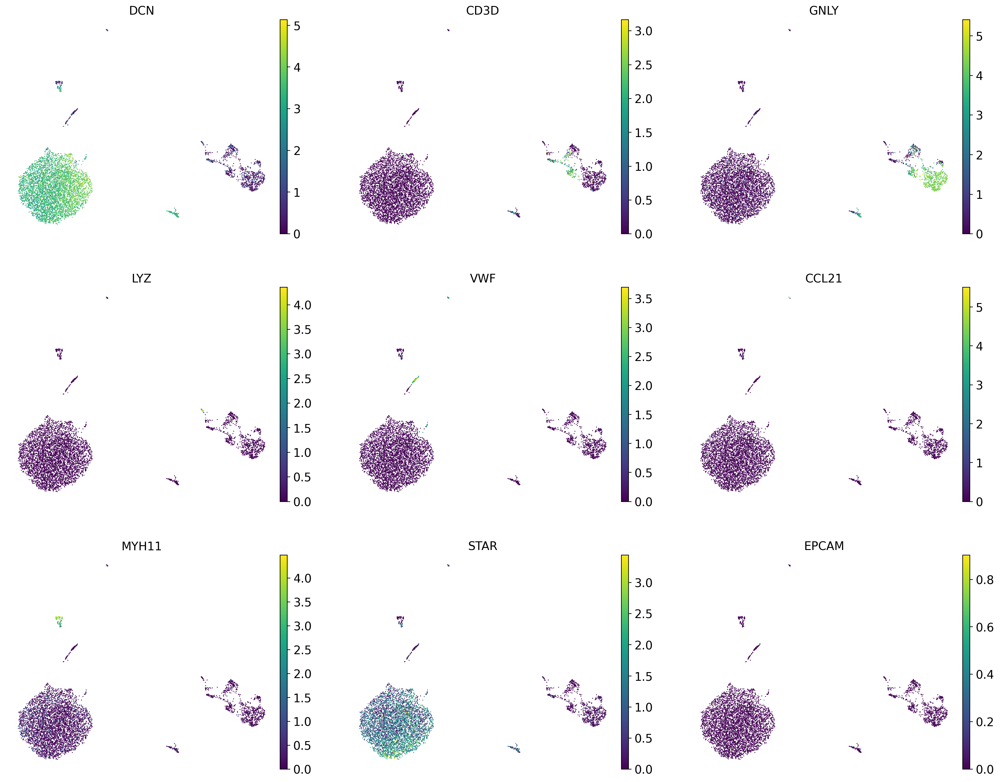

,DCN,CD3D,CD3E,GNLY,LYZ,CLDN5,CCL21,MYH11
leiden_1.0,,,,,,,,
0,3.08,0.00,0.01,0.04,0.00,0.01,0.00,0.16
1,3.41,0.00,0.00,0.07,0.00,0.00,0.01,0.06
2,3.41,0.00,0.01,0.06,0.00,0.00,0.01,0.14
3,3.78,0.00,0.01,0.05,0.00,0.00,0.00,0.14
4,0.96,0.00,0.00,0.07,0.03,0.76,0.00,0.07
5,3.30,0.00,0.00,0.07,0.00,0.00,0.01,0.18
6,3.27,0.00,0.01,0.05,0.00,0.00,0.01,0.13
7,3.40,0.00,0.00,0.05,0.00,0.00,0.00,0.23
8,0.39,0.63,1.50,1.30,0.00,0.01,0.00,0.06


,DCN,CD3D,CD3E,GNLY,LYZ,CLDN5,CCL21,MYH11
leiden_1.0,,,,,,,,
0,1.00,0.01,0.01,0.05,0.00,0.01,0.00,0.15
1,1.00,0.00,0.00,0.08,0.00,0.00,0.01,0.07
2,1.00,0.00,0.01,0.08,0.00,0.00,0.01,0.16
3,1.00,0.00,0.01,0.07,0.00,0.00,0.00,0.15
4,0.49,0.00,0.01,0.06,0.02,0.41,0.00,0.09
5,0.99,0.00,0.00,0.07,0.00,0.00,0.01,0.15
6,1.00,0.00,0.00,0.06,0.00,0.00,0.01,0.13
7,1.00,0.00,0.01,0.08,0.00,0.00,0.01,0.25
8,0.30,0.32,0.81,0.46,0.00,0.01,0.00,0.05


In [13]:
MARKERS = {
 'Stroma':['DCN','LUM','COL1A1','COL1A2','COL3A1','OGN'],
 'T cells':['CD3D','CD3E','TRAC','IL7R','TRDC'],
 'NK/cytotoxic':['NKG7','GNLY','KLRD1','PRF1'],
 'Myeloid':['LYZ','LST1','C1QA','HCK'],
 'Blood endothelium':['PECAM1','CLDN5','VWF','FLT1'],
 'Lymphatic endothelium':['PROX1','PDPN','CCL21'],
 'Smooth muscle':['ACTA2','MYH11','TAGLN','RGS5'],
 'Epithelial/ovarian':['EPCAM','KRT19','FOXL2','STAR','CYP11A1'],
}
sc.pl.dotplot(adata, MARKERS, groupby=CLUSTER, use_raw=False,
              standard_scale='var', figsize=(17, 7))

sc.pl.umap(adata, color=['DCN', 'CD3D', 'GNLY', 'LYZ', 'VWF', 'CCL21', 'MYH11', 'STAR', 'EPCAM'],
           ncols=3, use_raw=False, size=5)

known_genes = ['DCN', 'CD3D', 'CD3E', 'GNLY', 'LYZ', 'CLDN5', 'CCL21', 'MYH11']
expr = pd.DataFrame(adata[:, known_genes].X.toarray(), index=adata.obs_names, columns=known_genes)
marker_means = expr.groupby(adata.obs[CLUSTER], observed=True).mean()
marker_fractions = (expr > 0).groupby(adata.obs[CLUSTER], observed=True).mean()
display(marker_means.round(2))
display(marker_fractions.round(2))

На dotplot размер точки показывает долю клеток с ненулевой экспрессией. Цвет отражает среднюю лог-нормализованную экспрессию, приведённую к диапазону 0–1 отдельно для каждого гена. Поэтому цвета разных генов напрямую сравнивать нельзя.

По сочетанию маркеров я определила предполагаемые типы клеток. Кластеры 0–3 и 5-7 имеют стромальные маркеры, поэтому я оставила для них общее название. Оснований считать каждый из них отдельным типом клеток пока недостаточно. Кластер 13 оставила неопределённым: в нём одновременно выражены иммунные и стромальные маркеры. При изменении параметров кластеризации номера кластеров и их аннотацию нужно проверять заново.

| Кластер | Тип клеток | Маркеры | Обоснование |
|---|---|---|---|
| 0 | Stromal fibroblast-like | DCN, COL1A1, COL1A2; EGR1, JUN, JUNB | Есть маркеры стромы и immediate-early гены; возможен ответ на диссоциацию |
| 1 | Stromal fibroblast-like | DCN, COL1A1, COL1A2, OGN | Выражены несколько стромальных маркеров |
| 2 | Stromal fibroblast-like | DCN, COL1A1, COL1A2, STAR | Маркеры указывают на строму; одного STAR недостаточно для стероидогенного типа |
| 3 | Stromal fibroblast-like | DCN, LUM, COL1A1, COL1A2, COL3A1 | Хорошо выражены гены внеклеточного матрикса |
| 4 | Blood endothelial | PECAM1, VWF, FLT1, CLEC14A, ADGRL4 | Сочетание маркеров указывает на сосудистый эндотелий |
| 5 | Stromal fibroblast-like | DCN, COL1A1, COL1A2, COL3A1 | Есть стромальные маркеры; отдельный подтип не уточняла |
| 6 | Stromal fibroblast-like | DCN, COL1A1, COL1A2, OGN | Выражены маркеры стромы и компоненты матрикса |
| 7 | Stromal fibroblast-like | DCN, COL1A1, COL1A2, OGN | По сочетанию маркеров отнесла к строме |
| 8 | T cell | CD3E, TRAC, TRDC, GZMK | T-клеточные маркеры сочетаются с цитотоксическим профилем; возможен вклад gamma-delta T-клеток |
| 9 | Myeloid | LYZ, LST1, C1QA, HCK, MPEG1 | Есть несколько миелоидных маркеров; узкий подтип не уточняла |
| 10 | NK-like cytotoxic | GNLY, NKG7, KLRD1, PRF1, KLRF1 | Выражены NK-маркеры, CD3D встречается редко; из-за TRDC/CD3E оставила широкое название |
| 11 | NK-like cytotoxic | NKG7, KLRD1, PRF1, FCER1G, TMIGD2 | Преобладает NK-подобный профиль, но возможна примесь T-клеток |
| 12 | T cell | CD3D, CD3E, TRAC, IL7R | Есть несколько T-клеточных маркеров; по одному IL7R нельзя уверенно определить CD4 |
| 13 | Unknown mixed | DCN, COL1A1, COL1A2 вместе с CD3E, NKG7, GNLY | Смешаны стромальные и иммунные маркеры; возможны дублеты или контаминация |
| 14 | Vascular smooth muscle | ACTA2, MYH11, TAGLN | Совместная экспрессия сократительных генов указывает на гладкомышечные клетки |
| 15 | Lymphatic endothelial | PROX1, PDPN, CCL21, CLDN5 | Сочетание лимфатических и эндотелиальных маркеров поддерживает эту аннотацию |

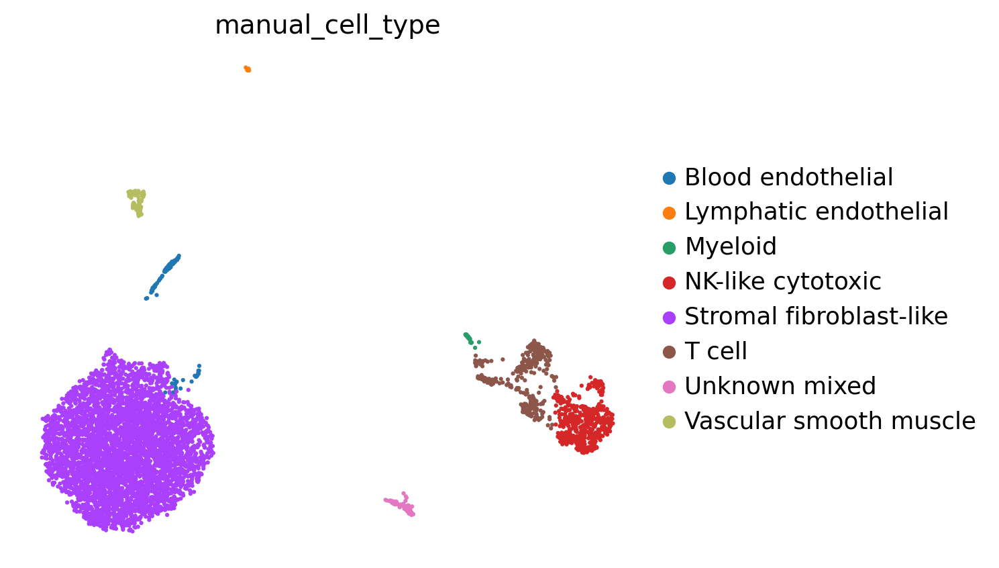

,count
manual_cell_type,
Stromal fibroblast-like,4776
NK-like cytotoxic,519
T cell,336
Blood endothelial,101
Unknown mixed,81
Vascular smooth muscle,71
Myeloid,28
Lymphatic endothelial,17


In [14]:
manual_annotations = {
    '0': 'Stromal fibroblast-like',
    '1': 'Stromal fibroblast-like',
    '2': 'Stromal fibroblast-like',
    '3': 'Stromal fibroblast-like',
    '4': 'Blood endothelial',
    '5': 'Stromal fibroblast-like',
    '6': 'Stromal fibroblast-like',
    '7': 'Stromal fibroblast-like',
    '8': 'T cell',
    '9': 'Myeloid',
    '10': 'NK-like cytotoxic',
    '11': 'NK-like cytotoxic',
    '12': 'T cell',
    '13': 'Unknown mixed',
    '14': 'Vascular smooth muscle',
    '15': 'Lymphatic endothelial'
}

adata.obs['manual_cell_type'] = (
    adata.obs['leiden_1.0'].astype(str).map(manual_annotations)
)

sc.pl.umap(adata, color='manual_cell_type')
display(adata.obs['manual_cell_type'].value_counts())

## 5. Автоматическая аннотация

Для сравнения использую CellTypist с моделью яичника из [Human Hormone Cell Atlas](https://hormonecellatlas.cellgeni.sanger.ac.uk/) ([Fei et al., 2026](https://doi.org/10.1126/science.aeb2672)). В ней есть стромальные, сосудистые и иммунные клетки человека. Поэтому она лучше подходит к этой ткани, чем иммунная модель из PBMC-примера.

Модель получает лог-нормализованную экспрессию. Majority voting отключаю, чтобы предсказания отдельных клеток не подгонялись под наши кластеры. Сохраняю исходные метки и максимальные оценки модели. При оценке меньше 0.5 ставлю `Uncertain`. Такая оценка не равна проверенной вероятности правильного ответа.

Пересечение обучающей выборки атласа с этой пробой отдельно не проверялось. Поэтому по совпадению аннотаций можно судить об их согласованности, но не об истинной точности.

CellTypist model with 11 cell types and 3000 features
    date: 2026-02-27 00:03:46.505174
    cell types: dendritic_cell, endothelial_cell_lymphatic, ..., vascular_smooth_muscle_cell
    features: A2M, AADAC, ..., ZYG11A


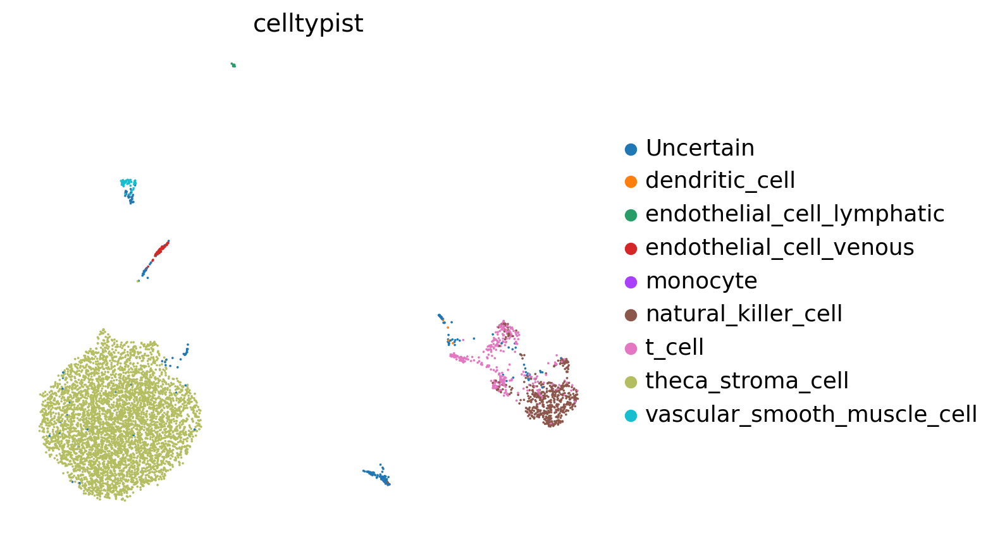

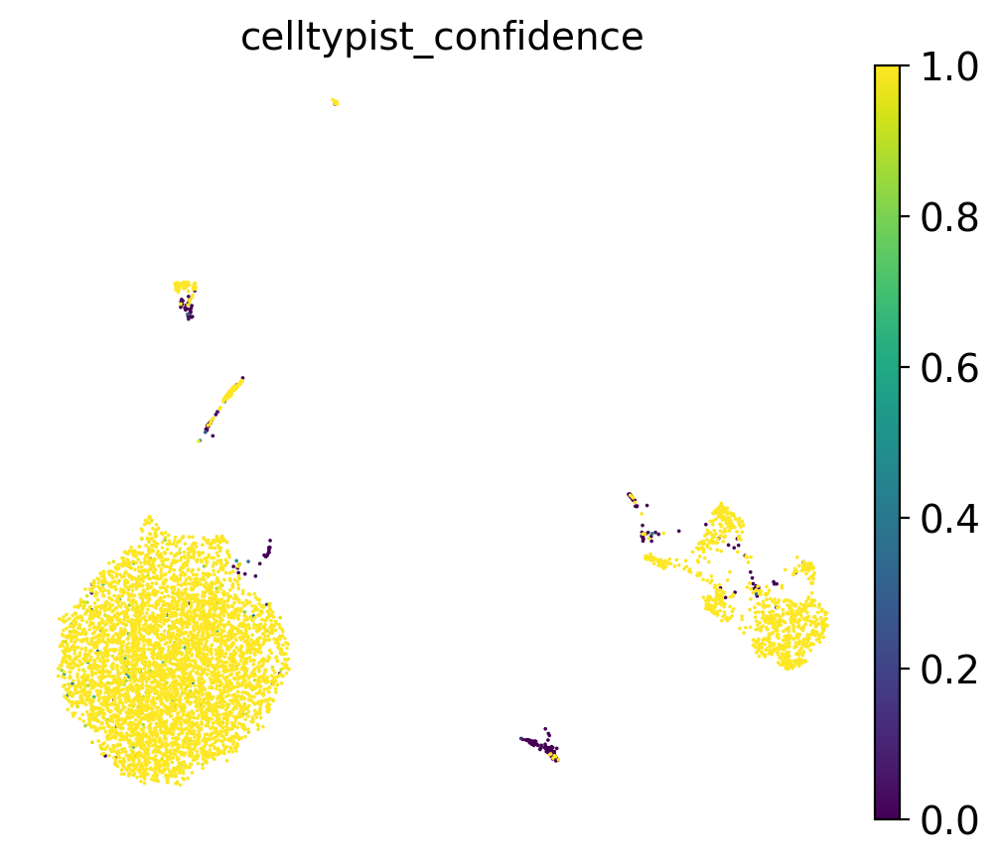

,count
celltypist,
theca_stroma_cell,4761
natural_killer_cell,506
t_cell,312
Uncertain,228
endothelial_cell_venous,54
vascular_smooth_muscle_cell,44
endothelial_cell_lymphatic,16
dendritic_cell,5
monocyte,3


In [15]:
model_url = 'https://cellgeni.cog.sanger.ac.uk/hormonecellatlas/download/CelltypistModel_celltype_level1.tar.gz'
bundle = DATA / 'CelltypistModel_celltype_level1.tar.gz'
model_path = DATA / 'Ovary_model_hvg3000_celltype_level1.pkl'

if not bundle.exists():
    urllib.request.urlretrieve(model_url, bundle)

# В архиве модели нескольких тканей. Читаю только файл для яичника.
with tarfile.open(bundle) as archive:
    model_file = archive.extractfile('celltype_level1/Ovary_model_hvg3000_celltype_level1.pkl')
    model_path.write_bytes(model_file.read())

model = celltypist.models.Model.load(model_path.resolve().as_posix())
print(model)
prediction = celltypist.annotate(adata.copy(), model=model, majority_voting=False)

adata.obs['celltypist_raw'] = prediction.predicted_labels['predicted_labels'].reindex(adata.obs_names)
adata.obs['celltypist_confidence'] = prediction.probability_matrix.max(axis=1).reindex(adata.obs_names)
adata.obs['celltypist'] = adata.obs['celltypist_raw'].astype(str)
adata.obs.loc[adata.obs['celltypist_confidence'] < 0.5, 'celltypist'] = 'Uncertain'

sc.pl.umap(adata, color='celltypist', size=7)
sc.pl.umap(adata, color='celltypist_confidence', size=7, cmap='viridis')
display(adata.obs['celltypist'].value_counts())

In [16]:
ct_cluster = pd.crosstab(adata.obs[CLUSTER], adata.obs['celltypist_raw'])
ct_manual = pd.crosstab(adata.obs['manual_cell_type'], adata.obs['celltypist_raw'])
display(ct_cluster)
display(ct_manual)
ct_cluster.to_csv(OUT / 'cluster_vs_celltypist.csv')
ct_manual.to_csv(OUT / 'manual_vs_celltypist.csv')

celltypist_raw,dendritic_cell,endothelial_cell_lymphatic,endothelial_cell_venous,macrophage,monocyte,natural_killer_cell,t_cell,theca_stroma_cell,vascular_smooth_muscle_cell
leiden_1.0,,,,,,,,,
0,0,0,0,0,0,0,0,692,0
1,0,0,0,0,0,0,0,643,0
2,0,0,0,0,0,0,0,934,0
3,0,0,0,0,0,0,0,861,0
4,0,0,57,0,0,0,0,44,0
5,0,0,0,0,0,0,0,652,0
6,0,0,0,0,0,0,0,426,0
7,0,0,0,0,0,0,0,568,0
8,0,0,0,0,0,30,121,6,0


celltypist_raw,dendritic_cell,endothelial_cell_lymphatic,endothelial_cell_venous,macrophage,monocyte,natural_killer_cell,t_cell,theca_stroma_cell,vascular_smooth_muscle_cell
manual_cell_type,,,,,,,,,
Blood endothelial,0,0,57,0,0,0,0,44,0
Lymphatic endothelial,0,16,0,0,0,0,0,1,0
Myeloid,4,0,0,1,4,1,0,18,0
NK-like cytotoxic,0,0,0,0,0,453,58,8,0
Stromal fibroblast-like,0,0,0,0,0,0,0,4776,0
T cell,3,0,0,0,0,51,259,23,0
Unknown mixed,0,0,0,0,0,9,0,72,0
Vascular smooth muscle,0,0,0,0,0,0,0,26,45


Кластеры 0–3 и 5–7 я отнесла к строме. CellTypist присвоил всем 4776 клеткам этих кластеров метку theca_stroma_cell. Это согласуется с ручной аннотацией на уровне стромальной линии, хотя название модели более узкое.

В T-клеточных кластерах 8 и 12 преобладает автоматическая метка t_cell. В NK-подобных кластерах 10 и 11 чаще встречается natural_killer_cell. Часть предсказаний между T и NK расходится, что может быть связано с общими цитотоксическими генами.

Для сосудистого кластера 4 модель предложила эндотелиальную метку для 57 из 101 клетки. В лимфатическом кластере 15 соответствующую метку получили 16 из 17 клеток, а в гладкомышечном кластере 14 — 45 из 71.

Для миелоидного кластера 9 результаты расходятся: 18 из 28 клеток модель отнесла к строме. По сочетанию LYZ, LST1, HCK, MPEG1 и C1QA я сохранила ручное название Myeloid.

Кластер 13 оставила неопределённым. Хотя исходное предсказание модели для 72 из 81 клетки — theca_stroma_cell, в нём одновременно выражены стромальные и иммунные маркеры. Возможны дублеты или контаминация.

После применения порога 0.5 у 228 клеток осталась метка Uncertain. В таблицах сопряжённости использованы исходные предсказания celltypist_raw без этого порога, поэтому столбца Uncertain в них нет.

В целом результаты согласуются для основных клеточных линий. Для спорных групп я сохранила более общие ручные названия по сочетанию маркеров.

## 6. Субкластеризация

Для более подробного разбора я выбрала стромальный кластер 0 при resolution=1.0. В нём 692 клетки. Для этого подмножества заново выбрала 1500 HVG, выполнила нормализацию, PCA, построение графа соседей и UMAP. Использовала 20 PC и 15 соседей.

При resolution=0.4 клетки остались в одной группе. Поэтому дополнительно проверила resolution=1.0, чтобы посмотреть, выделяются ли более мелкие группы.

,count
subcluster,
0,32
1,127
2,79
3,75
4,60
5,81
6,55
7,49
8,62


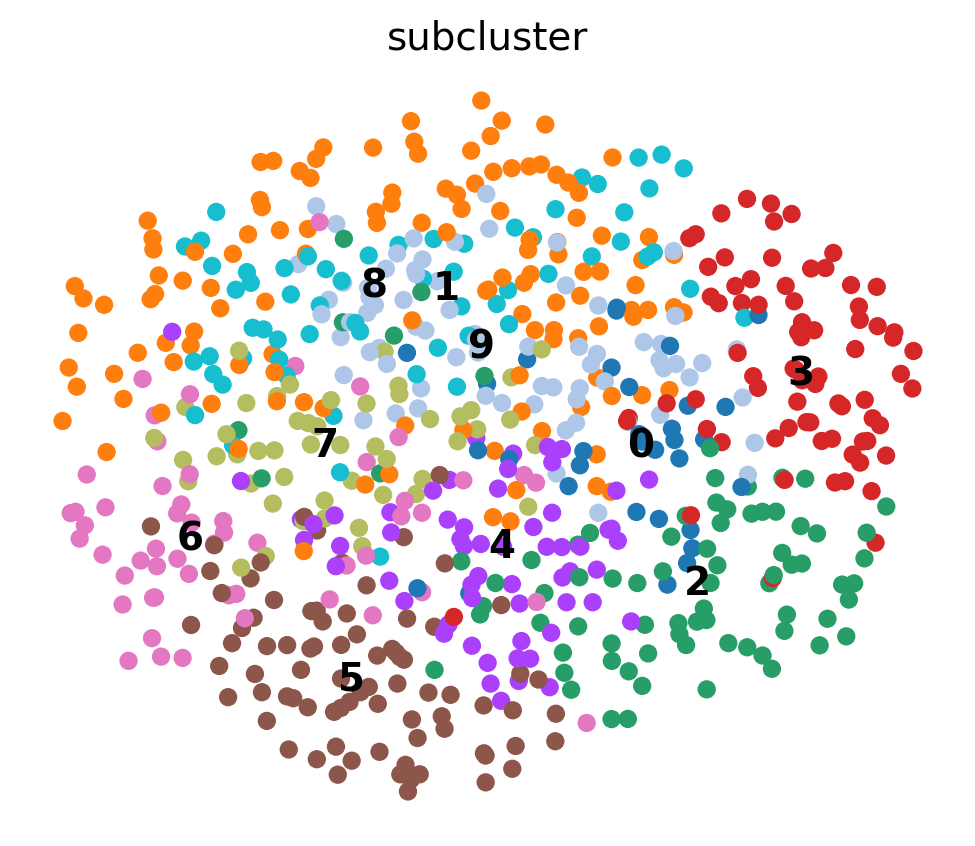

In [17]:
SUB_PARENT='0'
sub=adata[adata.obs[CLUSTER].astype(str)==SUB_PARENT].copy()
sub.X=sub.layers['counts'].copy()
sub.uns={}
sub.obsm.clear();sub.obsp.clear();sub.varm.clear()
sc.pp.filter_genes(sub,min_cells=3)
sc.pp.highly_variable_genes(sub,flavor='seurat_v3',n_top_genes=1500)
sc.pp.normalize_total(sub,target_sum=1e4)
sc.pp.log1p(sub)
sc.tl.pca(sub,n_comps=30,mask_var='highly_variable',random_state=42)
sc.pp.neighbors(sub,n_neighbors=15,n_pcs=20,random_state=42)
sc.tl.leiden(
    sub,
    resolution=1.0,
    key_added='subcluster',
    flavor='igraph',
    n_iterations=2,
    directed=False,
    random_state=42
)

sc.tl.umap(sub, random_state=42)

display(sub.obs['subcluster'].value_counts().sort_index())
sc.pl.umap(sub, color='subcluster', legend_loc='on data')

,n_cells
subcluster,
0,32
1,127
2,79
3,75
4,60
5,81
6,55
7,49
8,62


,group,names,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,0,REM2,6.5800,0.0000,0.0938,0.0015
1,0,NR4A2,2.1483,0.0003,0.6875,0.3333
2,0,EGR1,0.7919,0.0003,1.0000,1.0000
3,0,FKBP6,5.6934,0.0003,0.0625,0.0015
4,0,LINC01123,5.6867,0.0003,0.0625,0.0015
...,...,...,...,...,...,...
122954,9,SMYD3,1.8355,0.0132,0.2083,0.0597
122955,9,FOS,0.3712,0.0195,1.0000,1.0000
122956,9,AC136475.5,4.9029,0.0271,0.0417,0.0016
122957,9,IGSF9,4.2529,0.0271,0.0417,0.0016


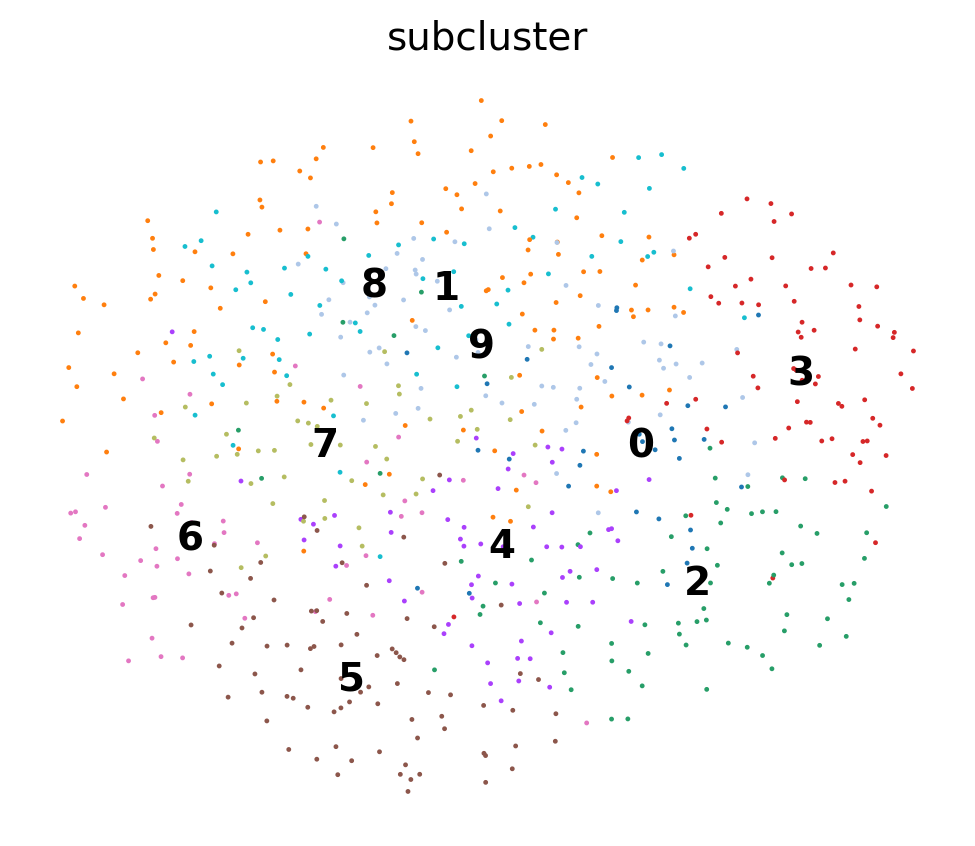

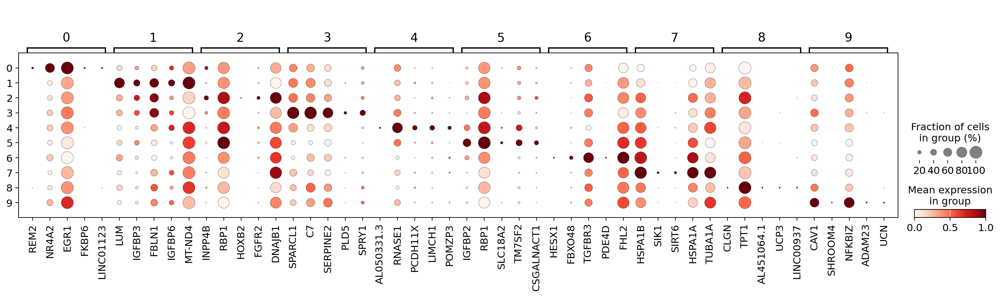

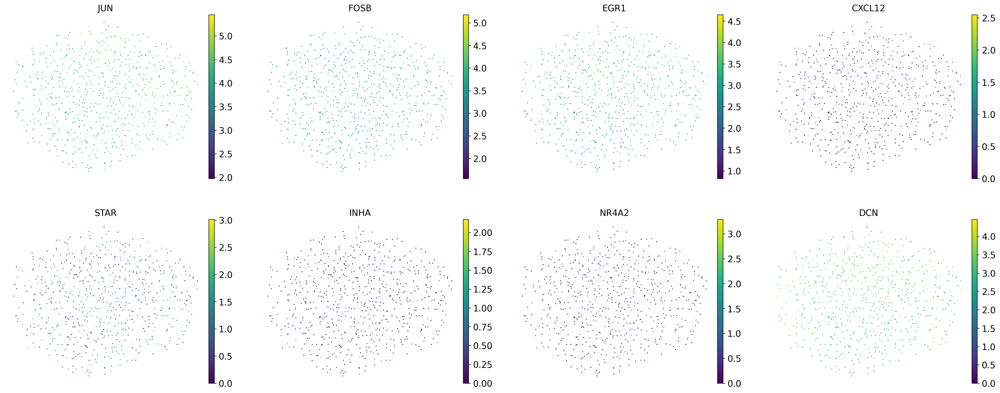

In [18]:
sc.tl.rank_genes_groups(sub,groupby='subcluster',method='wilcoxon',use_raw=False,
                        tie_correct=True,pts=True)
submarkers=sc.get.rank_genes_groups_df(sub,group=None)
submarkers.to_csv(OUT/'subcluster_markers_all.csv',index=False)
display(sub.obs.subcluster.value_counts().sort_index().to_frame('n_cells'))
display(submarkers.groupby('group',observed=True).head(10)[
 ['group','names','logfoldchanges','pvals_adj','pct_nz_group','pct_nz_reference']].round(4))
sc.pl.umap(sub,color='subcluster',legend_loc='on data',size=12)
sc.pl.rank_genes_groups_dotplot(sub,n_genes=5,groupby='subcluster',use_raw=False,
                               standard_scale='var',dendrogram=False)
state_markers=[g for g in ['JUN','FOSB','EGR1','CXCL12','STAR','INHA','NR4A2','DCN'] if g in sub.var_names]
sc.pl.umap(sub,color=state_markers,ncols=4,size=10,use_raw=False)

При resolution=0.4 все 692 клетки остались в одной группе. При увеличении resolution до 1.0 получилось 10 субкластеров размером от 32 до 127 клеток.

Между группами обнаружены различия в экспрессии. Например, среди наиболее высокоранжированных генов субкластера 0 есть NR4A2 и EGR1, субкластера 3 — SPARCL1, C7 и SERPINE2, а субкластера 7 — HSPA1A и TUBA1A. При этом некоторые высокоранжированные гены обнаружены лишь у небольшой доли клеток, поэтому по ним нельзя уверенно определять подтип.

DCN выражен по всему подмножеству и поддерживает общую стромальную аннотацию. JUN, FOSB и EGR1 также встречаются во многих клетках, поэтому по этим генам не видно чётких границ между состояниями клеток.

После повторного отбора HVG и построения графа внутри одной популяции стали заметны более мелкие различия. Однако группы на UMAP сильно перекрываются, а число субкластеров зависит от resolution. Поэтому я сохранила их числовые обозначения и не стала присваивать отдельные клеточные типы.

Субкластеризация показала неоднородность экспрессии внутри стромального кластера, но убедительно выделить самостоятельные биологические подтипы по этим результатам не удалось.

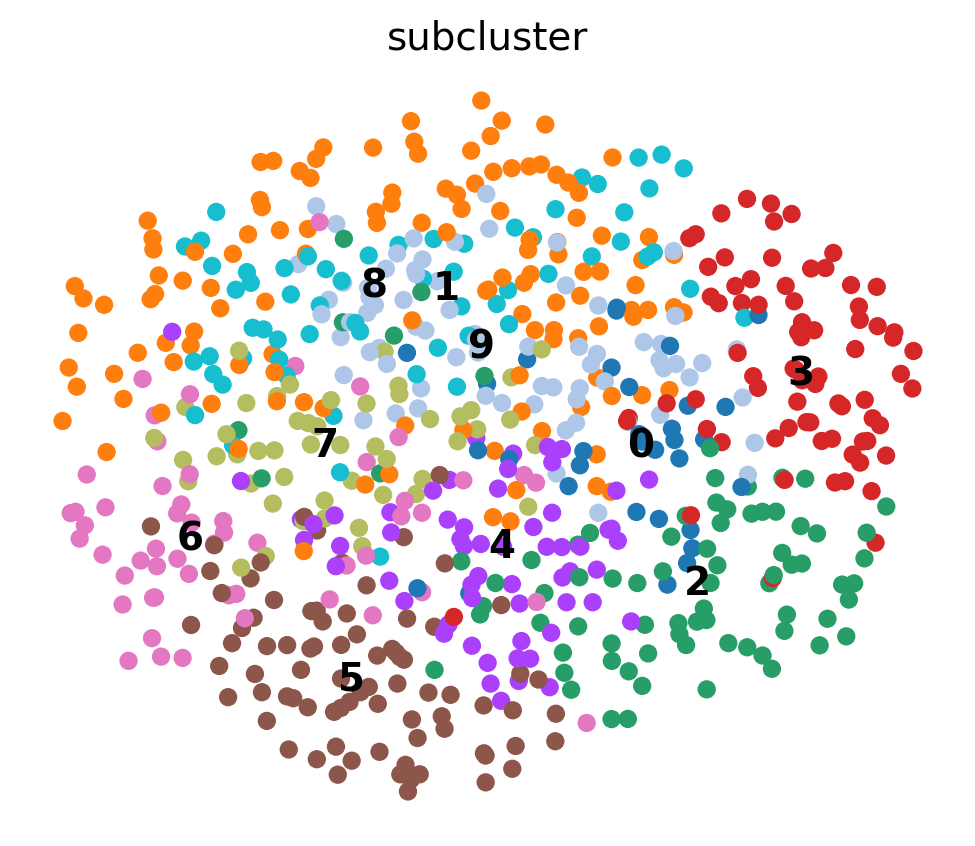

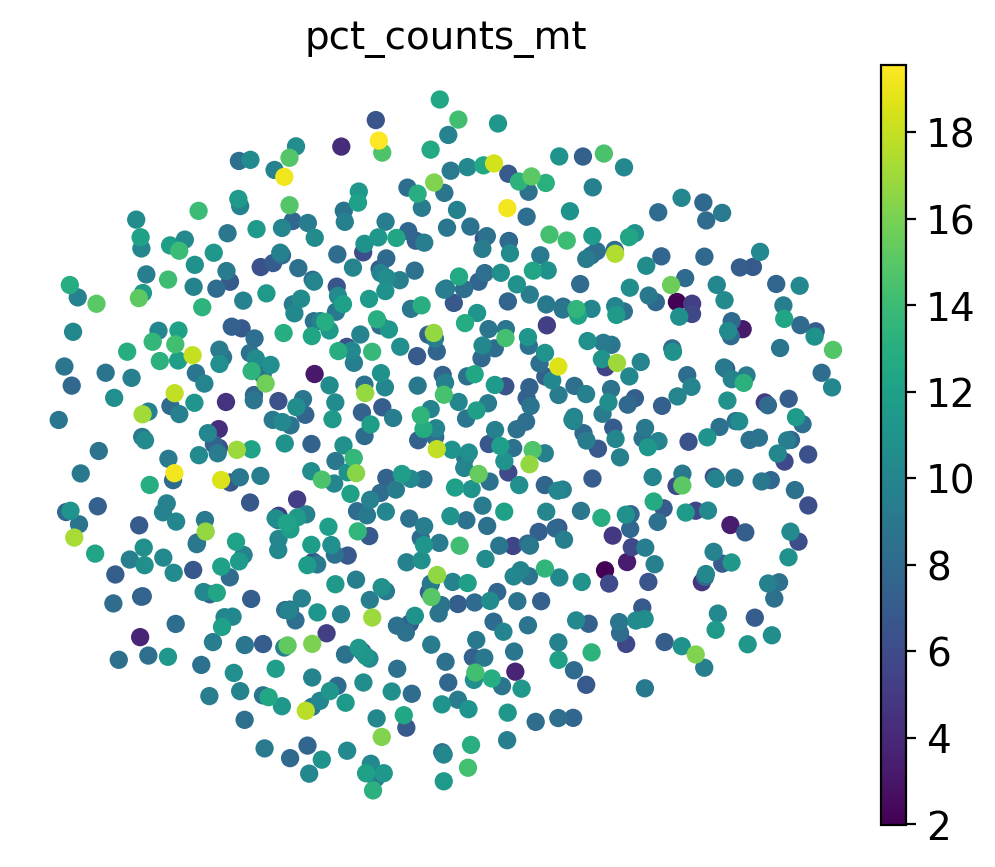

,total_counts,n_genes_by_counts,pct_counts_mt
subcluster,,,
0,7683.0,2254.5,8.703362
1,8716.0,2211.0,10.182940
2,8602.0,2210.0,8.910300
3,8410.0,2304.0,8.848485
4,9605.0,2494.0,9.428642
5,8944.0,2290.0,10.111230
6,8608.0,2243.0,9.690722
7,8059.0,2182.0,9.374284
8,7702.0,2089.0,9.600781


In [19]:
sub.obs['subcluster_state'] = (
    'Stroma subcluster ' + sub.obs['subcluster'].astype(str)
)

sc.pl.umap(sub, color='subcluster', legend_loc='on data')
sc.pl.umap(sub, color='pct_counts_mt')

display(
    sub.obs.groupby('subcluster', observed=True)[qc_columns].median()
)

Медианная доля митохондриальных UMI в субкластерах составляет примерно 8.7–10.2%. На UMAP не видно отдельной области с резко повышенными значениями. Медианное число обнаруженных генов находится в пределах 2089–2494. Эти показатели не дают явных оснований считать какой-либо субкластер группой клеток низкого качества, хотя полностью исключить технические различия по ним нельзя.

## 7. Генные программы

Я выбрала цитотоксичность, интерфероновый ответ и внеклеточный матрикс. Цитотоксические гены взяты из примера семинара. Интерфероновый набор сокращён из [MSigDB HALLMARK_INTERFERON_ALPHA_RESPONSE](https://www.gsea-msigdb.org/gsea/msigdb/human/geneset/HALLMARK_INTERFERON_ALPHA_RESPONSE.html). Матриксный набор составлен из генов структурных компонентов матрикса, включая [COL3A1](https://www.ncbi.nlm.nih.gov/gene/1281).

`score_genes` сравнивает среднюю экспрессию выбранных генов с контрольными генами сходного уровня экспрессии. Поэтому score может быть отрицательным. Сравниваю клетки внутри каждой программы; численные значения разных программ напрямую не сопоставляю. [Описание score_genes](https://scanpy.readthedocs.io/en/stable/generated/scanpy.tl.score_genes.html).

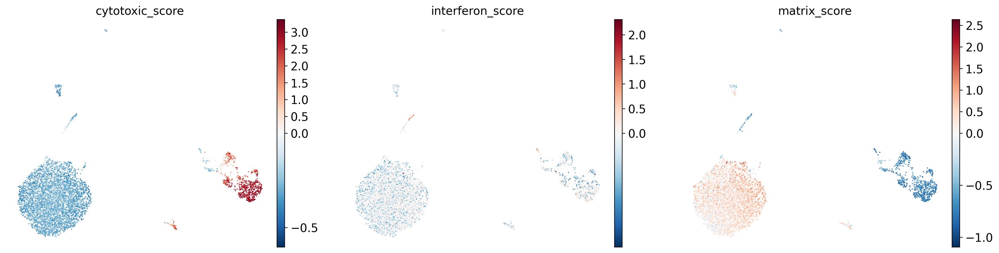

In [20]:
cytotoxic_genes = ['NKG7', 'PRF1', 'GZMB', 'GNLY', 'CTSW']
interferon_genes = ['ISG15', 'IFIT1', 'IFIT2', 'IFIT3', 'MX1', 'IFI6', 'OAS1', 'OAS2', 'IFI44L']
matrix_genes = ['COL1A1', 'COL1A2', 'COL3A1', 'COL6A1', 'COL6A2', 'DCN', 'LUM', 'FN1']

sc.tl.score_genes(adata, gene_list=cytotoxic_genes, score_name='cytotoxic_score',
                  use_raw=False, random_state=42, ctrl_size=50)
sc.tl.score_genes(adata, gene_list=interferon_genes, score_name='interferon_score',
                  use_raw=False, random_state=42, ctrl_size=50)
sc.tl.score_genes(adata, gene_list=matrix_genes, score_name='matrix_score',
                  use_raw=False, random_state=42, ctrl_size=50)

scores = ['cytotoxic_score', 'interferon_score', 'matrix_score']
sc.pl.umap(adata, color=scores, ncols=3, size=7, cmap='RdBu_r', vcenter=0)

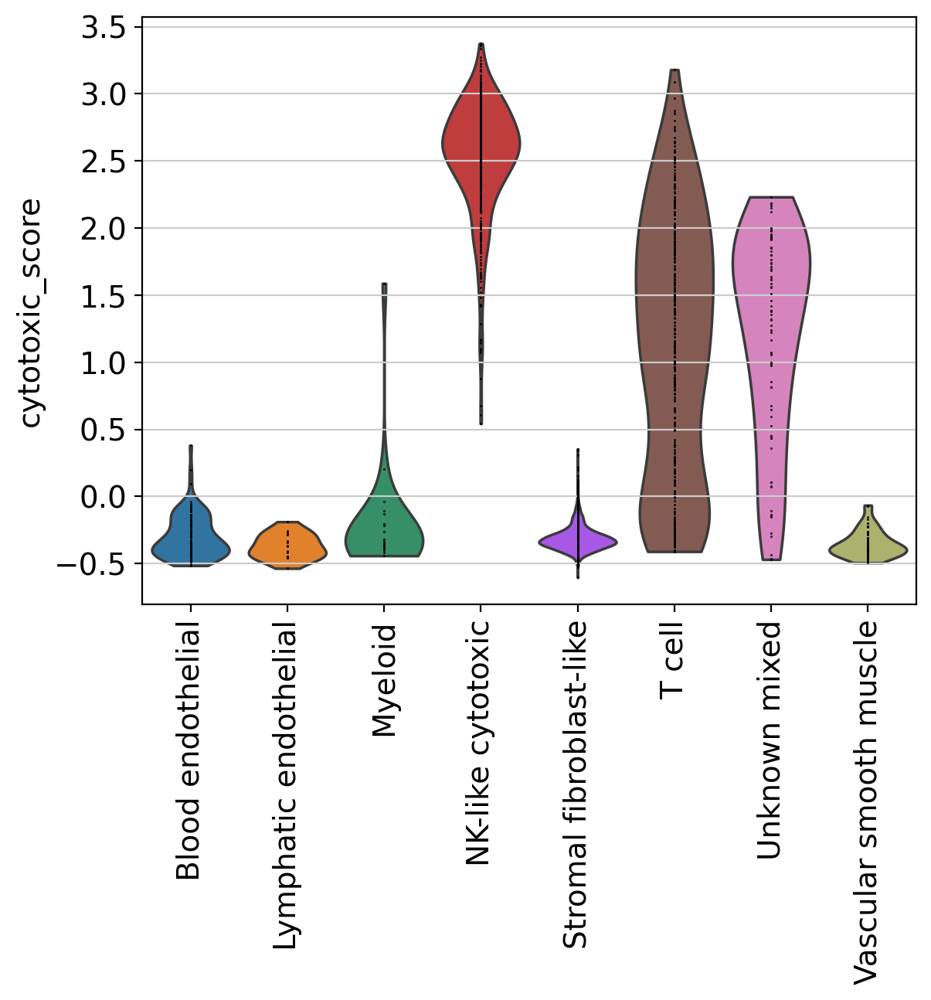

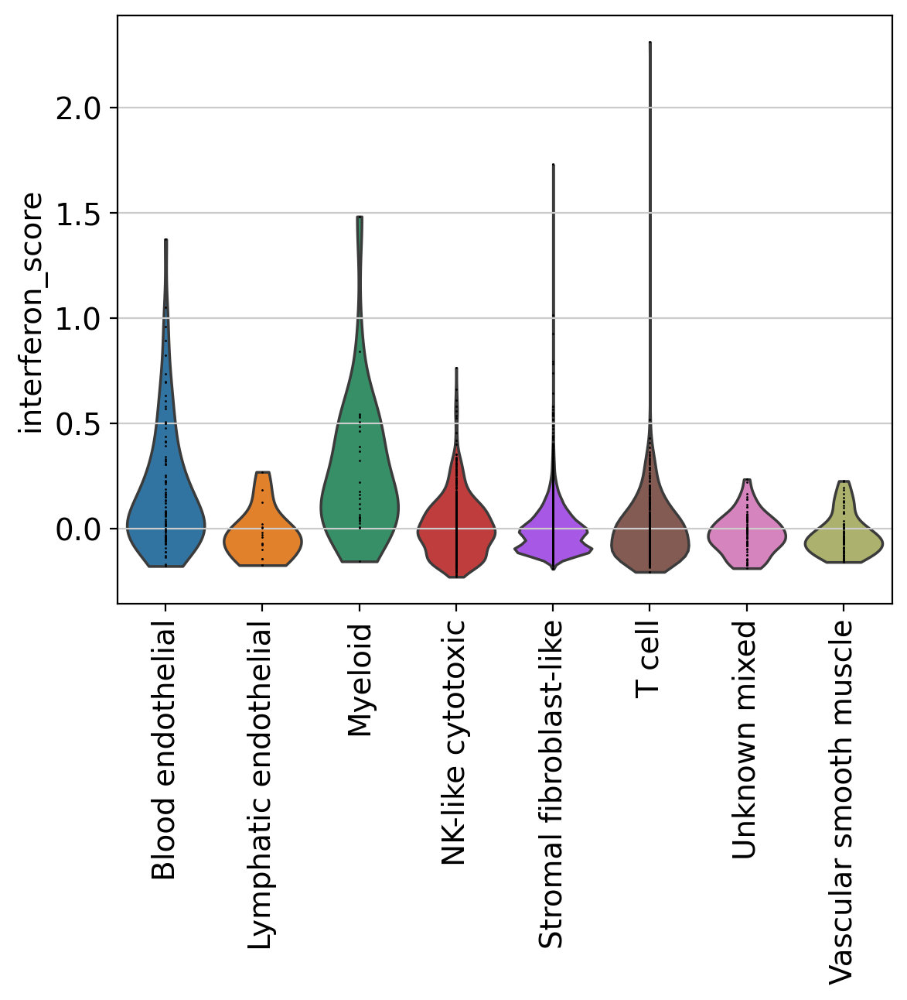

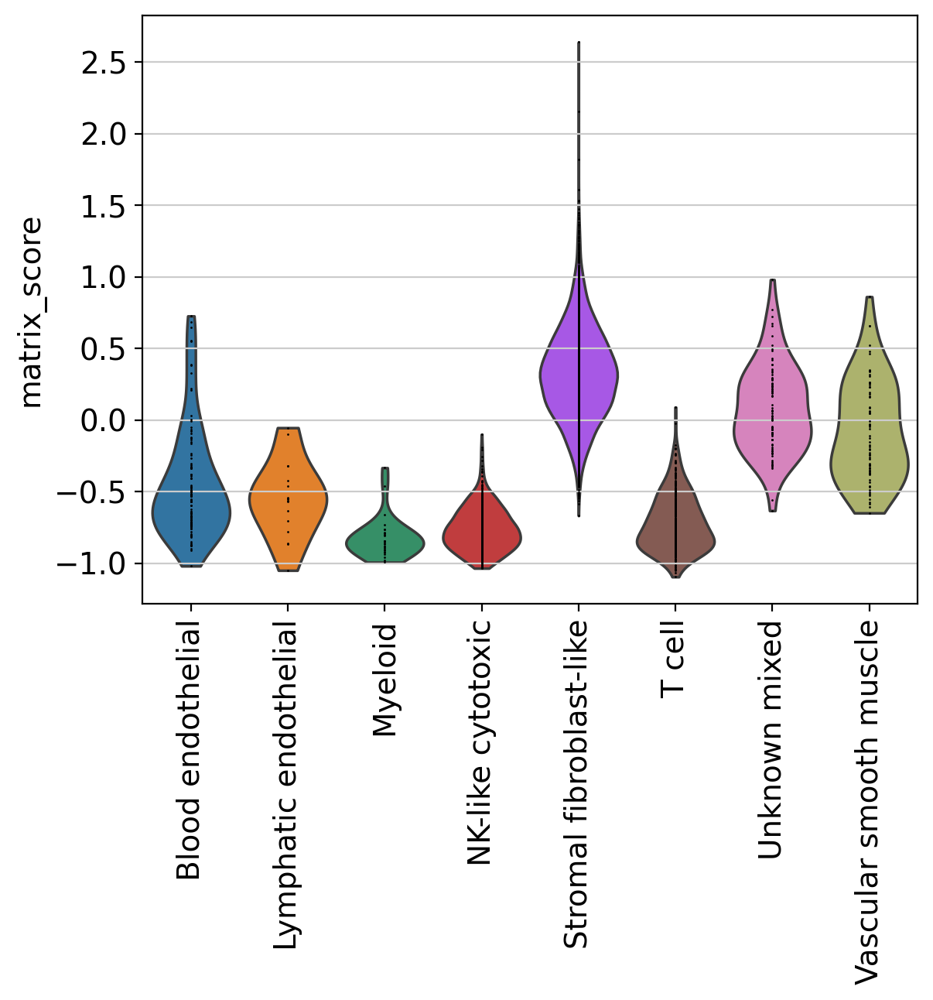

,cytotoxic_score,interferon_score,matrix_score
manual_cell_type,,,
Blood endothelial,-0.298,0.178,-0.444
Lymphatic endothelial,-0.372,-0.025,-0.550
Myeloid,-0.229,0.272,-0.821
NK-like cytotoxic,2.524,0.015,-0.760
Stromal fibroblast-like,-0.314,-0.006,0.326
T cell,1.103,0.005,-0.718
Unknown mixed,1.196,-0.025,0.083
Vascular smooth muscle,-0.352,-0.025,-0.075


,cytotoxic_score,interferon_score,matrix_score
manual_cell_type,,,
Blood endothelial,-0.346,0.076,-0.534
Lymphatic endothelial,-0.372,-0.040,-0.551
Myeloid,-0.346,0.152,-0.849
NK-like cytotoxic,2.595,-0.007,-0.777
Stromal fibroblast-like,-0.328,-0.021,0.313
T cell,1.155,-0.021,-0.750
Unknown mixed,1.382,-0.025,0.045
Vascular smooth muscle,-0.378,-0.050,-0.127


,cytotoxic_score,interferon_score,matrix_score
leiden_1.0,,,
0,-0.298,-0.017,0.136
1,-0.283,-0.008,0.293
2,-0.322,-0.012,0.276
3,-0.338,0.012,0.555
4,-0.298,0.178,-0.444
5,-0.299,-0.011,0.338
6,-0.303,0.003,0.261
7,-0.341,-0.008,0.362
8,1.188,-0.009,-0.766


In [21]:
sc.pl.violin(adata, 'cytotoxic_score', groupby='manual_cell_type', rotation=90, jitter=False)
sc.pl.violin(adata, 'interferon_score', groupby='manual_cell_type', rotation=90, jitter=False)
sc.pl.violin(adata, 'matrix_score', groupby='manual_cell_type', rotation=90, jitter=False)

score_means = adata.obs.groupby('manual_cell_type', observed=True)[scores].mean()
score_medians = adata.obs.groupby('manual_cell_type', observed=True)[scores].median()
display(score_means.round(3))
display(score_medians.round(3))
display(adata.obs.groupby(CLUSTER, observed=True)[scores].mean().round(3))
score_means.to_csv(OUT / 'program_mean_by_type.csv')

Цитотоксический score оказался самым высоким у NK-подобных клеток: среднее значение составило 2.524, медиана — 2.595. У T-клеток он тоже повышен: среднее 1.103, медиана 1.155. Это согласуется с наличием цитотоксической программы у обеих популяций и показывает, почему одного такого score недостаточно, чтобы отличить NK от T-клеток.

Матриксный score выше всего у стромальных клеток: среднее 0.326, медиана 0.313. Среди отдельных кластеров наибольшее среднее значение получено для стромального кластера 3 — 0.555. Это поддерживает стромальную аннотацию и указывает на различия в выраженности матриксной программы внутри стромы.

Интерфероновый score в среднем выше у миелоидных клеток — 0.272, затем у сосудистого эндотелия — 0.178. Медианы составили 0.152 и 0.076 соответственно. При этом распределения широкие: программа выражена неодинаково у разных клеток одной популяции. По этим значениям нельзя установить причину интерферонового ответа или сделать вывод об инфекции.

В смешанном кластере 13 повышен цитотоксический score — 1.196, а средний матриксный score остаётся положительным — 0.083. Вместе с результатами анализа маркеров это поддерживает решение оставить кластер неопределённым. Возможные дублеты или контаминацию нужно проверять отдельно.

Генные программы помогли уточнить ручную аннотацию: матриксная сигнатура поддержала стромальную линию, цитотоксическая показала общие свойства NK- и части T-клеток, а интерфероновая выявила различия в состоянии популяций. Высокий score отражает относительную экспрессию выбранных генов и сам по себе не доказывает выполнение функции.

## 8. Итоги

Для сравнения вывожу UMAP двух разрешений, ручную и автоматическую аннотацию. Отдельный UMAP субкластеров рассчитан заново, поэтому его оси нельзя сопоставлять с общей проекцией.

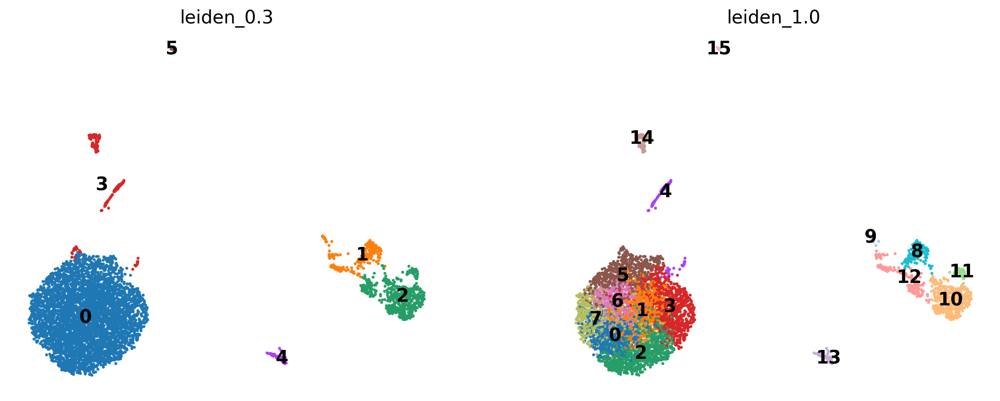

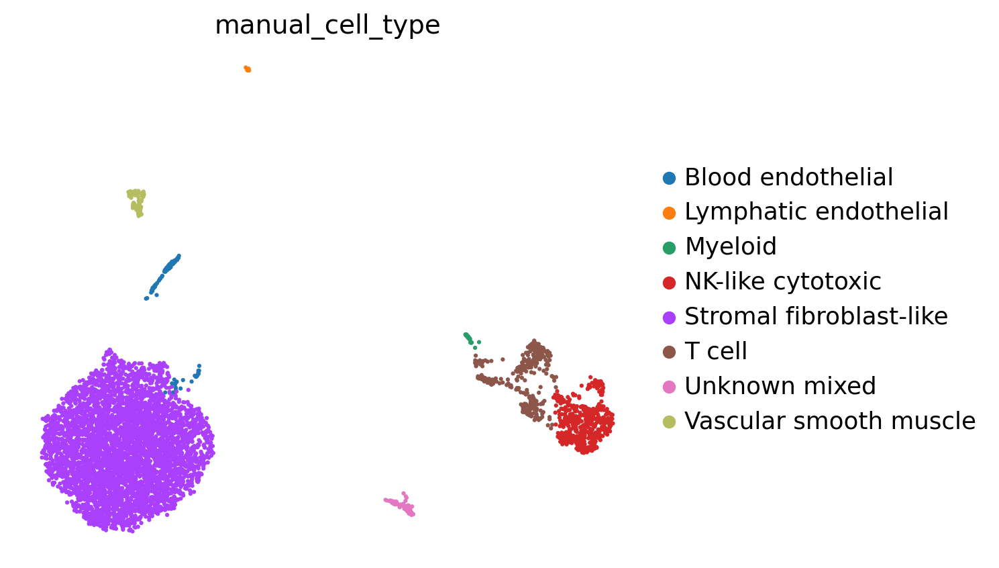

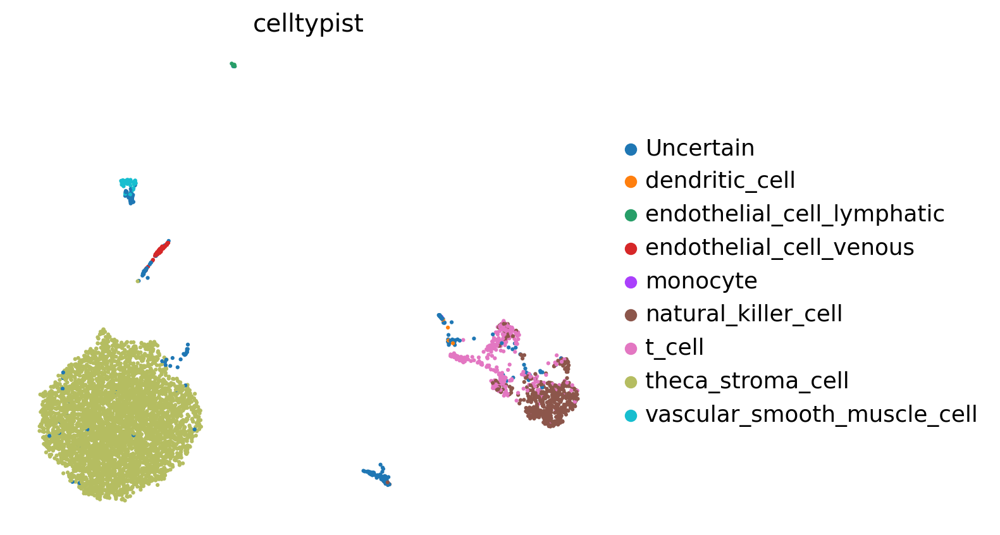

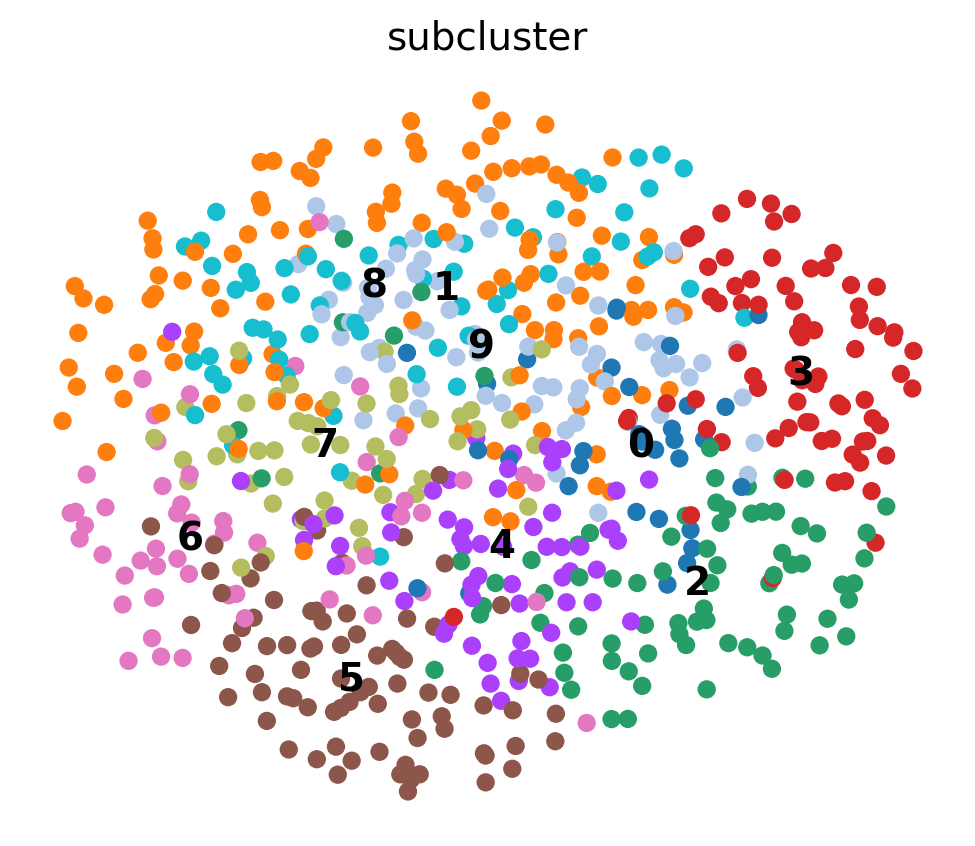

In [22]:
sc.pl.umap(adata, color=['leiden_0.3', 'leiden_1.0'], ncols=2, legend_loc='on data')
sc.pl.umap(adata, color='manual_cell_type')
sc.pl.umap(adata, color='celltypist')
sc.pl.umap(sub, color='subcluster', legend_loc='on data')

### Выводы

После фильтрации осталось 5929 из 6370 клеток и 17 704 гена. При resolution=0.3 получилось 6 кластеров, а при resolution=1.0 — 16.

В пробе преобладает строма: к ней отнесено 4776 клеток. Также выделены 519 NK-подобных клеток, 336 T-клеток, 101 клетка сосудистого эндотелия, 71 гладкомышечная клетка, 28 миелоидных клеток и 17 клеток лимфатического эндотелия. Ещё 81 клетка вошла в кластер со смешанными маркерами. Отдельные эпителиальные или гранулёзные популяции уверенно выделить не удалось. Это не означает, что их нет во всём яичнике.

Для аннотации я использовала сочетания маркеров: DCN, LUM и коллагены для стромы; CD3D, CD3E и TRAC для T-клеток; GNLY, NKG7 и KLRD1 для NK-подобных; LYZ, HCK и MPEG1 для миелоидных; MYH11, ACTA2 и TAGLN для гладкомышечных клеток. Сосудистый эндотелий определяла по PECAM1, VWF и FLT1, лимфатический — по PROX1, PDPN и CCL21.

CellTypist в основном поддержал ручную аннотацию широких клеточных линий. Расхождения были заметнее в небольшом миелоидном кластере, смешанной группе и между T- и NK-подобными клетками. В спорных случаях я сохранила более общее название по сочетанию маркеров. После применения порога оценки 0.5 модель оставила 228 клеток с меткой Uncertain.

Для субкластеризации я выбрала стромальный кластер 0, содержащий 692 клетки. При resolution=0.4 он остался одной группой, а при resolution=1.0 разделился на 10 субкластеров размером от 32 до 127 клеток. Между ними есть различия в экспрессии, но убедительно определить самостоятельные биологические подтипы не удалось. Поэтому я сохранила числовые обозначения субкластеров.

Генные программы дополнили аннотацию. Цитотоксический score был выше всего у NK-подобных клеток и также повышен у T-клеток. Матриксная программа сильнее выражена в строме, интерфероновая — в среднем у миелоидных клеток и сосудистого эндотелия. Сочетание цитотоксического и матриксного сигналов в кластере 13 поддержало решение оставить его неопределённым.

Выводы относятся к одному образцу. В работе не проверялись различия между донорами и не выполнялось отдельное удаление дублетов. Аннотация основана на экспрессии генов без экспериментального подтверждения, а высокие значения генных scores сами по себе не доказывают выполнение функции.

### Сохранение

Сохраняю аннотированную матрицу, отдельный объект субкластеризации и таблицу ручной аннотации. Ноутбук с графиками можно скачать в Colab через «Файл → Скачать → Скачать IPYNB».

In [23]:
adata.write_h5ad(OUT / 'GSM5599220_after_annotation.h5ad', compression='gzip')
sub.write_h5ad(OUT / 'GSM5599220_cluster0_subclustered.h5ad', compression='gzip')
pd.Series(manual_annotations, name='manual_cell_type').to_csv(OUT / 'manual_cluster_annotation.csv')
adata.obs.to_csv(OUT / 'cell_metadata.csv')
print('Результаты сохранены в папке', OUT)

Результаты сохранены в папке results_ovary


### Источники

- Матрица: [GEO GSM5599220](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM5599220), [серия GSE184880](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE184880).
- Исходное исследование: Xu J. et al. *Single-Cell RNA Sequencing Reveals the Tissue Architecture in Human High-Grade Serous Ovarian Cancer*. Clinical Cancer Research, 2022. [DOI](https://doi.org/10.1158/1078-0432.CCR-22-0296).